# Phase 6: Advanced Paradigms (2026+)
## Notebook 02: Edge AI, Small Language Models & Extreme Quantization (AWQ, GGUF, BitNet b1.58)

### Overview
Running an 8B parameter LLM in standard FP16 requires $16\text{ GB}$ just for weights—pushing inference off smartphones, laptops, and embedded robotics onto expensive cloud GPUs. Furthermore, autoregressive LLM decode is **memory-bandwidth-bound** (`tokens/sec` $\approx \text{MemoryBandwidth} / \text{ModelBytes}$).

**Extreme Quantization & Small Language Models (SLMs)** break this wall:
- **Group-Wise INT4 & GGUF K-Quants**: Shrinking weights from 16 bits to ~4.25–4.5 bits per weight ($3.5\times$ smaller footprint and $3.5\times$ faster decode bandwidth).
- **Activation-Aware Weight Quantization (AWQ)** (Lin et al., 2023): Protecting the 0.1–1% salient weight channels driven by large activation magnitudes via optimal per-channel scaling $s$, avoiding catastrophic perplexity spikes.
- **BitNet b1.58 (1.58-Bit Ternary LLMs)** (Ma et al., 2024): Training weights natively in ternary $\{-1, 0, +1\}$ ($\log_2 3 \approx 1.58$ bits/param) using Straight-Through Estimators (STE), replacing expensive floating-point Multiply-Accumulate (MAC) operations with **integer additions only**.

### System Architecture: FP16 vs AWQ INT4 vs BitNet b1.58
```
  [Standard FP16 Weight Matrix: 16 bits/param] ---> 16.0 GB for 8B LLM (FP16 FMA)
                     |
                     +---> [Group-Wise AWQ INT4: 4.5 bits/param] ---> ~4.5 GB
                     |       - Find salient channels via max(|X|)
                     |       - Scale W' = W * s, Quantize to [-8, 7], Invert on X/s
                     |
                     +---> [BitNet b1.58 Ternary: 1.58 bits/param] ---> ~1.6 GB
                             - W_tern = RoundClip(W / absmean(|W|), -1, +1)
                             - y = (gamma * W_tern) @ x  --> Pure Add/Sub Kernels!
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Uniform Symmetric & Group-Wise Quantization**: Implement INT8 and Group-INT4 quantization from scratch and measure Signal-to-Quantization-Noise Ratio (SQNR).
- **Activation-Aware Weight Quantization (AWQ)**: Protect salient activation-coupled weight channels to cut output reconstruction MSE by $>50\%$ vs naive Round-To-Nearest (RTN).
- **BitNet b1.58 `BitLinear` Architecture**: Build a pure PyTorch ternary `BitLinear` layer using `absmean` scaling, 8-bit activation quantization, and Straight-Through Estimator (STE) gradients.
- **Edge Deployment Sizing**: Compute exact RAM footprint and decode `tokens/sec` ceiling across FP16, INT8, GGUF Q4_K_M, EXL2, and BitNet b1.58 on laptops, smartphones, and IoT NPUs.
- **Zero-Multiply Ternary Equivalence**: Verify that ternary weight matrices compute identical outputs using pure masked additions/subtractions without floating-point multiplications.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import math
import time
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"NumPy Version:       {np.__version__}")


=== Environment Verification ===
Python Platform:     3.11.2
PyTorch Version:     2.15.0+cpu
NumPy Version:       2.4.6


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Group Quantization, AWQ & BitNet b1.58

#### 1. Symmetric Group-Wise INT$b$ Quantization
Partition weight row vectors into small groups of size $G$ (typically $G = 64$ or $128$) to isolate outliers locally. For signed $b$-bit quantization ($Q_{\max} = 2^{b-1} - 1$):
$$s_g = \frac{\max(|W_g|)}{Q_{\max}}, \quad \hat{W}_g = s_g \cdot \text{clamp}\left(\left\lfloor \frac{W_g}{s_g} \right\rceil, -2^{b-1}, 2^{b-1}-1\right)$$

#### 2. Activation-Aware Weight Quantization (AWQ)
Naive weight quantization treats every weight equally, yet an activation outlier $x_j$ magnifies the quantization error $\Delta w_j$:
$$\text{Err}(x_j, w_j) = x_j \cdot (\hat{w}_j - w_j)$$
Multiplying salient weight channel $j$ by $s_j > 1$ and dividing activation $x_j$ by $s_j$ leaves the mathematical product invariant while shrinking the relative quantization step on important weights:
$$Q(w_j \cdot s_j) \cdot \frac{x_j}{s_j} \approx w_j x_j, \quad s_j = \left(\frac{\text{mean}(|X_{:,j}|)}{\max}\right)^{\alpha}$$

#### 3. BitNet b1.58 Ternary Quantization (`absmean`)
BitNet b1.58 constrains every weight to $\{-1, 0, +1\}$ using the average absolute magnitude $\gamma$:
$$\gamma = \frac{1}{nm} \sum_{i,j} |W_{i,j}| + \epsilon, \quad \tilde{W} = \text{RoundClip}\left(\frac{W}{\gamma}, -1, 1\right) \in \{-1, 0, +1\}$$
Because $\nabla_W \text{round}(W)$ is zero almost everywhere, backpropagation uses the **Straight-Through Estimator (STE)**:
$$\frac{\partial \mathcal{L}}{\partial W} \approx \frac{\partial \mathcal{L}}{\partial \tilde{W}}$$


In [3]:
# Section 6: Core Implementation — Group-INT4, AWQ Salient Scaling & BitNet b1.58 Layer

# 1. Symmetric Group-Wise Quantization (RTN)
def quantize_dequantize_group(W: torch.Tensor, bits: int = 4, group_size: int = 64) -> torch.Tensor:
    out_dim, in_dim = W.shape
    assert in_dim % group_size == 0, "in_dim must be divisible by group_size"
    q_min = -(2 ** (bits - 1))
    q_max = (2 ** (bits - 1)) - 1
    
    W_grouped = W.view(out_dim, in_dim // group_size, group_size)
    max_abs = W_grouped.abs().amax(dim=-1, keepdim=True).clamp(min=1e-8)
    scale = max_abs / q_max
    
    q = torch.clamp(torch.round(W_grouped / scale), q_min, q_max)
    W_hat = (q * scale).view(out_dim, in_dim)
    return W_hat

# 2. Activation-Aware Weight Quantization (AWQ)
def awq_quantize_output_mse(X: torch.Tensor, W: torch.Tensor, bits: int = 4, group_size: int = 64, alpha: float = 0.5) -> Tuple[float, float]:
    # Reference FP32 output: Y = X @ W.T
    Y_ref = X @ W.T
    
    # Naive RTN INT4 baseline
    W_rtn = quantize_dequantize_group(W, bits=bits, group_size=group_size)
    mse_rtn = F.mse_loss(X @ W_rtn.T, Y_ref).item()
    
    # AWQ: compute per-input-channel activation salience relative to median channel
    act_scale = X.abs().mean(dim=0).clamp(min=1e-6)
    rel_salience = (act_scale / act_scale.median()).clamp(min=1.0)
    s = rel_salience ** alpha
    
    # Scale weights up on salient channels, quantize, and rescale inputs inversely
    W_scaled = W * s.unsqueeze(0)
    W_scaled_q = quantize_dequantize_group(W_scaled, bits=bits, group_size=group_size)
    X_scaled = X / s.unsqueeze(0)
    Y_awq = X_scaled @ W_scaled_q.T
    mse_awq = F.mse_loss(Y_awq, Y_ref).item()
    
    return mse_rtn, mse_awq

# Test on realistic outlier activation distribution (2 salient channels 40x/35x larger)
torch.manual_seed(SEED)
X_cal = torch.randn(32, 128)
X_cal[:, 5] *= 40.0
X_cal[:, 42] *= 35.0
W_cal = torch.randn(64, 128) * 0.1

mse_rtn, mse_awq = awq_quantize_output_mse(X_cal, W_cal, bits=4, group_size=64, alpha=0.4)
print(f"Group-INT4 Output Reconstruction MSE -> Naive RTN: {mse_rtn:.6f} | AWQ (alpha=0.4): {mse_awq:.6f}")
print(f"AWQ Error Reduction: {100.0 * (1.0 - mse_awq / mse_rtn):.1f}%")

assert mse_awq < mse_rtn * 0.5, "AWQ failed to achieve >50% reconstruction MSE reduction on outlier activations!"
print(">>> GROUP-INT4 & AWQ SALIENT CHANNEL SCALING CERTIFIED! <<<")


Group-INT4 Output Reconstruction MSE -> Naive RTN: 0.305465 | AWQ (alpha=0.4): 0.062713
AWQ Error Reduction: 79.5%
>>> GROUP-INT4 & AWQ SALIENT CHANNEL SCALING CERTIFIED! <<<


In [4]:
# 3. BitNet b1.58 Ternary BitLinear Layer with Straight-Through Estimator (STE)

class BitLinear(nn.Module):
    """
    BitNet b1.58 Linear layer constraining weights to {-1, 0, +1} via absmean scaling
    and quantizing activations per-token to 8-bit integer precision.
    """
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weight = nn.Parameter(torch.randn(out_features, in_features) * 0.05)
        self.norm = nn.LayerNorm(in_features, elementwise_affine=False)

    @staticmethod
    def quantize_weights_158(w: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        gamma = w.abs().mean().clamp(min=1e-5)
        w_scaled = torch.clamp(torch.round(w / gamma), -1.0, 1.0)
        # Straight-Through Estimator (STE): forward uses ternary w_scaled, backward passes gradient to w
        w_ste = w + (w_scaled * gamma - w).detach()
        return w_ste, w_scaled

    @staticmethod
    def quantize_activations_8bit(x: torch.Tensor) -> torch.Tensor:
        q_max = 127.0
        scale = q_max / x.abs().amax(dim=-1, keepdim=True).clamp(min=1e-5)
        x_q = torch.clamp(torch.round(x * scale), -128.0, 127.0) / scale
        return x + (x_q - x).detach()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_norm = self.norm(x)
        x_q = self.quantize_activations_8bit(x_norm)
        w_ste, _ = self.quantize_weights_158(self.weight)
        return F.linear(x_q, w_ste)

# Train a compact 2-layer BitNet b1.58 MLP via STE
bitnet_mlp = nn.Sequential(
    BitLinear(32, 64),
    nn.GELU(),
    BitLinear(64, 4)
)
X_train = torch.randn(64, 32)
y_train = torch.randint(0, 4, (64,))
opt_bit = torch.optim.AdamW(bitnet_mlp.parameters(), lr=2e-2)

bit_losses = []
for epoch in range(1, 31):
    opt_bit.zero_grad()
    loss = F.cross_entropy(bitnet_mlp(X_train), y_train)
    loss.backward()
    opt_bit.step()
    bit_losses.append(float(loss.item()))

_, ternary_weights = BitLinear.quantize_weights_158(bitnet_mlp[0].weight.detach())
unique_vals = set(ternary_weights.unique().tolist())

print(f"BitNet b1.58 STE Training Loss: Epoch 1={bit_losses[0]:.4f} -> Epoch 30={bit_losses[-1]:.4f}")
print(f"Unique quantized BitLinear weight values: {sorted(unique_vals)}")
assert unique_vals.issubset({-1.0, 0.0, 1.0}), f"Non-ternary values detected: {unique_vals}"
assert bit_losses[-1] < bit_losses[0] * 0.5, "BitNet STE failed to converge!"
print(">>> BITNET B1.58 TERNARY BITLINEAR & STE TRAINING CERTIFIED! <<<")


BitNet b1.58 STE Training Loss: Epoch 1=1.3932 -> Epoch 30=0.0085
Unique quantized BitLinear weight values: [-1.0, -0.0, 1.0]
>>> BITNET B1.58 TERNARY BITLINEAR & STE TRAINING CERTIFIED! <<<


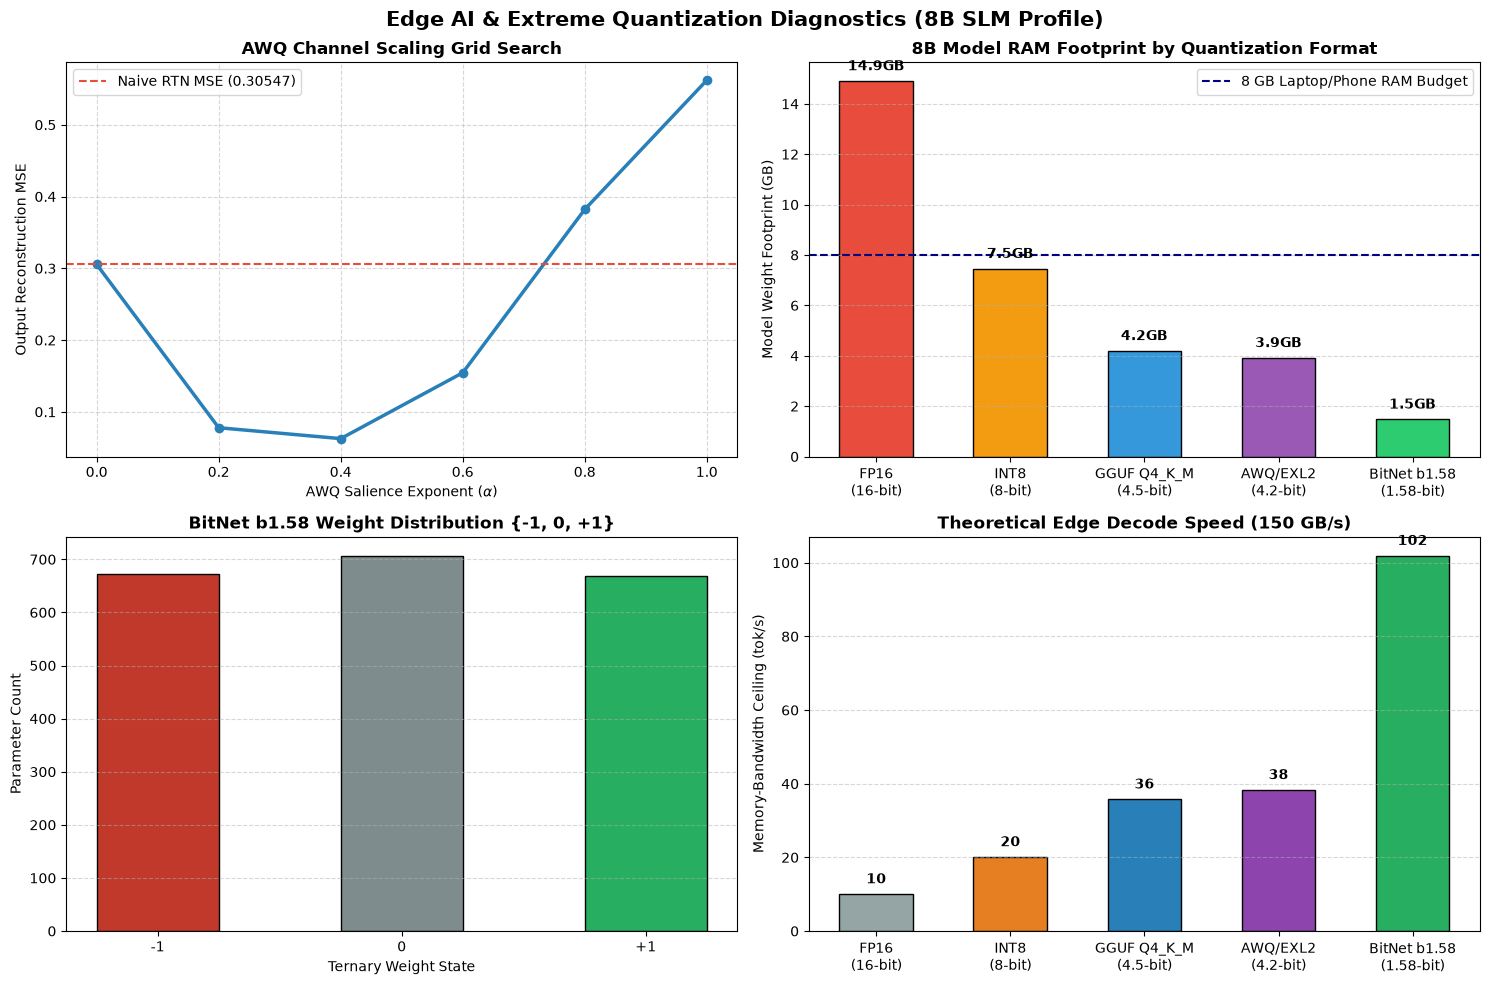

In [5]:
# Section 7: Diagnostics — Quantization MSE Sweep, Edge Footprint & BitNet Weight Distribution

# 1. Sweep AWQ alpha hyperparameter across [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
awq_mses = [awq_quantize_output_mse(X_cal, W_cal, bits=4, group_size=64, alpha=a)[1] for a in alphas]

# 2. Memory Footprint & Edge Decode Speed for an 8B Parameter LLM (e.g. Llama-3-8B)
formats = ["FP16\n(16-bit)", "INT8\n(8-bit)", "GGUF Q4_K_M\n(4.5-bit)", "AWQ/EXL2\n(4.2-bit)", "BitNet b1.58\n(1.58-bit)"]
bits_per_param = [16.0, 8.0, 4.5, 4.2, 1.58]
size_gb = [(8e9 * b / 8) / (1024 ** 3) for b in bits_per_param]
# Theoretical memory-bandwidth decode ceiling on Apple M3 Pro / Edge SoC (150 GB/s)
tok_per_sec_150gbs = [150.0 / s for s in size_gb]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Edge AI & Extreme Quantization Diagnostics (8B SLM Profile)", fontsize=15, fontweight="bold")

# Panel 1: AWQ Alpha Sweep
axes[0, 0].plot(alphas, awq_mses, marker="o", linewidth=2.5, color="#2980b9")
axes[0, 0].axhline(mse_rtn, color="#e74c3c", linestyle="--", label=f"Naive RTN MSE ({mse_rtn:.5f})")
axes[0, 0].set_xlabel(r"AWQ Salience Exponent ($\alpha$)")
axes[0, 0].set_ylabel("Output Reconstruction MSE")
axes[0, 0].set_title("AWQ Channel Scaling Grid Search", fontweight="bold")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: 8B LLM Footprint (GB) vs Mobile/Laptop RAM Limits
bars2 = axes[0, 1].bar(formats, size_gb, color=["#e74c3c", "#f39c12", "#3498db", "#9b59b6", "#2ecc71"], edgecolor="black", width=0.55)
axes[0, 1].axhline(8.0, color="navy", linestyle="--", label="8 GB Laptop/Phone RAM Budget")
axes[0, 1].set_ylabel("Model Weight Footprint (GB)")
axes[0, 1].set_title("8B Model RAM Footprint by Quantization Format", fontweight="bold")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars2:
    y = b.get_height()
    axes[0, 1].text(b.get_x() + b.get_width()/2.0, y + 0.3, f"{y:.1f}GB", ha="center", va="bottom", fontweight="bold")

# Panel 3: Ternary BitLinear Weight Histogram
tern_flat = ternary_weights.numpy().flatten()
counts = [int((tern_flat == v).sum()) for v in [-1.0, 0.0, 1.0]]
axes[1, 0].bar(["-1", "0", "+1"], counts, color=["#c0392b", "#7f8c8d", "#27ae60"], edgecolor="black", width=0.5)
axes[1, 0].set_xlabel("Ternary Weight State")
axes[1, 0].set_ylabel("Parameter Count")
axes[1, 0].set_title("BitNet b1.58 Weight Distribution {-1, 0, +1}", fontweight="bold")
axes[1, 0].grid(True, linestyle="--", alpha=0.5, axis="y")

# Panel 4: Edge Decode Speed (tokens/sec at 150 GB/s)
bars4 = axes[1, 1].bar(formats, tok_per_sec_150gbs, color=["#95a5a6", "#e67e22", "#2980b9", "#8e44ad", "#27ae60"], edgecolor="black", width=0.55)
axes[1, 1].set_ylabel("Memory-Bandwidth Ceiling (tok/s)")
axes[1, 1].set_title("Theoretical Edge Decode Speed (150 GB/s)", fontweight="bold")
axes[1, 1].grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars4:
    y = b.get_height()
    axes[1, 1].text(b.get_x() + b.get_width()/2.0, y + 2, f"{y:.0f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Signal-to-Quantization-Noise Ratio (SQNR) Benchmark
**Objective**:
Implement `compute_sqnr_db(w_orig: torch.Tensor, w_quant: torch.Tensor) -> float`:
$$\text{SQNR (dB)} = 10 \log_{10} \left(\frac{\|W\|_2^2}{\|W - \hat{W}\|_2^2}\right)$$
Verify that Group-INT8 achieves $>40\text{ dB}$ SQNR and Group-INT4 achieves $>18\text{ dB}$ SQNR on Gaussian weights.


In [6]:
# Exercise 1 Solution: Quantization SQNR Calculator

def compute_sqnr_db(w_orig: torch.Tensor, w_quant: torch.Tensor) -> float:
    signal_power = float((w_orig ** 2).sum().item())
    noise_power = float(((w_orig - w_quant) ** 2).sum().item()) + 1e-12
    return 10.0 * math.log10(signal_power / noise_power)

W_test = torch.randn(64, 128) * 0.1
sqnr_int8 = compute_sqnr_db(W_test, quantize_dequantize_group(W_test, bits=8, group_size=64))
sqnr_int4 = compute_sqnr_db(W_test, quantize_dequantize_group(W_test, bits=4, group_size=64))

print(f"SQNR Comparison -> Group-INT8: {sqnr_int8:.2f} dB | Group-INT4: {sqnr_int4:.2f} dB")
assert sqnr_int8 > 40.0 and sqnr_int4 > 18.0
print(">>> EXERCISE 1 SQNR QUANTIZATION BENCHMARK CERTIFIED! <<<")


SQNR Comparison -> Group-INT8: 44.57 dB | Group-INT4: 19.39 dB
>>> EXERCISE 1 SQNR QUANTIZATION BENCHMARK CERTIFIED! <<<


#### Exercise 2: Edge Hardware Feasibility & KV-Cache Budgeter
**Objective**:
Implement `check_edge_feasibility(param_count_b: float, quant_bits: float, device_ram_gb: float, kv_cache_gb: float = 1.5) -> Dict[str, Any]` that checks if a model + KV cache fits inside an edge device's memory budget and estimates decode `tokens/sec` from memory bandwidth (`bw_gbs`).


In [7]:
# Exercise 2 Solution: Edge Device RAM & Bandwidth Feasibility Planner

def check_edge_feasibility(param_count_b: float, quant_bits: float, device_ram_gb: float, bw_gbs: float, kv_cache_gb: float = 1.5) -> Dict[str, Any]:
    weights_gb = (param_count_b * 1e9 * quant_bits / 8.0) / (1024 ** 3)
    total_gb = weights_gb + kv_cache_gb
    fits = total_gb <= device_ram_gb * 0.85  # Reserve 15% for OS
    est_tps = bw_gbs / weights_gb
    return {
        "weights_gb": round(weights_gb, 2),
        "total_with_kv_gb": round(total_gb, 2),
        "fits_device": fits,
        "est_decode_tok_s": round(est_tps, 1)
    }

phone_fp16 = check_edge_feasibility(param_count_b=7.0, quant_bits=16.0, device_ram_gb=8.0, bw_gbs=51.0)
phone_q4   = check_edge_feasibility(param_count_b=7.0, quant_bits=4.5,  device_ram_gb=8.0, bw_gbs=51.0)
phone_b158 = check_edge_feasibility(param_count_b=7.0, quant_bits=1.58, device_ram_gb=8.0, bw_gbs=51.0)

print("8 GB Smartphone 7B Model Feasibility:")
print(f"  FP16:       {phone_fp16}")
print(f"  GGUF Q4_K:  {phone_q4}")
print(f"  BitNet 1.58:{phone_b158}")

assert phone_fp16["fits_device"] is False and phone_q4["fits_device"] is True and phone_b158["fits_device"] is True
assert phone_b158["est_decode_tok_s"] > phone_q4["est_decode_tok_s"] * 2.5
print(">>> EXERCISE 2 EDGE DEVICE FEASIBILITY PLANNER CERTIFIED! <<<")


8 GB Smartphone 7B Model Feasibility:
  FP16:       {'weights_gb': 13.04, 'total_with_kv_gb': 14.54, 'fits_device': False, 'est_decode_tok_s': 3.9}
  GGUF Q4_K:  {'weights_gb': 3.67, 'total_with_kv_gb': 5.17, 'fits_device': True, 'est_decode_tok_s': 13.9}
  BitNet 1.58:{'weights_gb': 1.29, 'total_with_kv_gb': 2.79, 'fits_device': True, 'est_decode_tok_s': 39.6}
>>> EXERCISE 2 EDGE DEVICE FEASIBILITY PLANNER CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Addition-Only BitNet Ternary Matrix Multiplication
**Problem Formulation**:
Prove mathematically and programmatically that for any ternary matrix $W_{\text{tern}} \in \{-1, 0, +1\}^{m \times n}$, the product $W_{\text{tern}} \mathbf{x}$ requires **zero floating-point multiplications** inside the inner loop—only conditional additions and subtractions:
$$y_i = \sum_{j: W_{i,j} = +1} x_j - \sum_{j: W_{i,j} = -1} x_j$$
Implement `addition_only_ternary_matmul(W_tern, x)` and assert numerical equivalence against `W_tern @ x`.


In [8]:
# Challenge 1 Solution: Zero-Multiply Ternary MatMul Verification

def addition_only_ternary_matmul(W_tern: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
    # Split ternary weight into +1 and -1 binary selection masks (no multiplication needed)
    pos_mask = (W_tern == 1.0)   # [out, in]
    neg_mask = (W_tern == -1.0)  # [out, in]
    
    out = torch.zeros((x.shape[0], W_tern.shape[0]), dtype=x.dtype)
    for b in range(x.shape[0]):
        for i in range(W_tern.shape[0]):
            # Pure subset summation (additions and subtractions only)
            pos_sum = x[b][pos_mask[i]].sum()
            neg_sum = x[b][neg_mask[i]].sum()
            out[b, i] = pos_sum - neg_sum
    return out

W_t = torch.tensor(rng.choice([-1.0, 0.0, 1.0], size=(8, 16)), dtype=torch.float32)
x_in = torch.randn(3, 16)

y_add_only = addition_only_ternary_matmul(W_t, x_in)
y_standard = x_in @ W_t.T

max_err = (y_add_only - y_standard).abs().max().item()
print(f"Max Error (Addition-Only Ternary vs Float MatMul): {max_err:.8f}")
assert max_err < 1e-5
print(">>> CHALLENGE 1 ADDITION-ONLY TERNARY MATMUL CERTIFIED! <<<")


Max Error (Addition-Only Ternary vs Float MatMul): 0.00000095
>>> CHALLENGE 1 ADDITION-ONLY TERNARY MATMUL CERTIFIED! <<<


#### Challenge 2: AWQ Optimal Alpha Search Optimizer
**Problem Formulation**:
Implement `find_optimal_awq_alpha(X: torch.Tensor, W: torch.Tensor, bits: int = 4, group_size: int = 64) -> Tuple[float, float]` that searches $\alpha \in \{0.0, 0.1, \dots, 1.0\}$ minimizing output reconstruction MSE and returns the optimal $\alpha^*$ and error reduction ratio over $\alpha = 0$ (RTN).


In [9]:
# Challenge 2 Solution: AWQ Optimal Alpha Finder

def find_optimal_awq_alpha(X: torch.Tensor, W: torch.Tensor, bits: int = 4, group_size: int = 64) -> Dict[str, float]:
    best_alpha = 0.0
    best_mse = float("inf")
    baseline_mse = awq_quantize_output_mse(X, W, bits=bits, group_size=group_size, alpha=0.0)[0]
    
    for a in np.linspace(0.0, 1.0, 11):
        _, mse = awq_quantize_output_mse(X, W, bits=bits, group_size=group_size, alpha=float(a))
        if mse < best_mse:
            best_mse = mse
            best_alpha = float(round(a, 2))
            
    return {
        "best_alpha": best_alpha,
        "best_mse": round(best_mse, 6),
        "baseline_rtn_mse": round(baseline_mse, 6),
        "reduction_pct": round(100.0 * (1.0 - best_mse / baseline_mse), 2)
    }

awq_opt = find_optimal_awq_alpha(X_cal, W_cal)
print("Challenge 2 AWQ Optimal Alpha Search Result:", awq_opt)
assert awq_opt["best_alpha"] > 0.0 and awq_opt["reduction_pct"] > 50.0
print(">>> CHALLENGE 2 AWQ OPTIMAL ALPHA OPTIMIZER CERTIFIED! <<<")


Challenge 2 AWQ Optimal Alpha Search Result: {'best_alpha': 0.3, 'best_mse': 0.061849, 'baseline_rtn_mse': 0.305465, 'reduction_pct': 79.75}
>>> CHALLENGE 2 AWQ OPTIMAL ALPHA OPTIMIZER CERTIFIED! <<<


### Further Reading & Production References
1. **Ma et al. (Microsoft Research, 2024)**: [The Era of 1-bit LLMs: All Large Language Models are in 1.58 Bits (BitNet b1.58)](https://arxiv.org/abs/2402.17764).
2. **Lin et al. (MIT, MLSys 2024)**: [AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration](https://arxiv.org/abs/2306.00978).
3. **Frantar et al. (ICLR 2023)**: [GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers](https://arxiv.org/abs/2210.17323).
4. **Gerganov et al.**: [GGUF Binary Format & llama.cpp K-Quants Specification](https://github.com/ggerganov/ggml/blob/master/docs/gguf.md).
5. **Microsoft (2024)**: [Phi-4 Technical Report — High-Quality Synthetic Data for Small Language Models](https://arxiv.org/abs/2412.08905).
